# Book Recommender System on a Medallion Data Lake

**Data Mining Lab Assignment 2.** Raw Book-Crossing data → **Bronze** (raw copy) → **Silver** (cleaned) → **Gold** (model-ready) → **item-based collaborative filtering** recommender.

| Layer | What it holds | Format |
|---|---|---|
| `bronze/` | The three source files, untouched, plus an `ingestion_timestamp` | Parquet |
| `silver/` | Deduplicated, validated, cleaned and filtered tables | Parquet |
| `gold/` | Sparse user × book rating matrix, book lookup, user/book aggregates | `.npz` + Parquet |

**How to run (Google Colab or locally):** run all cells top to bottom. If `BX-Users.csv`, `BX-Books.csv` and `BX-Book-Ratings.csv` are already in the working folder (e.g. uploaded to `/content` in Colab), they are used as-is; otherwise the notebook downloads the official zip.

In [1]:
import csv
import html
import re
import urllib.request
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import sparse
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)

# Plot style: one blue for single-series charts, recessive grid, no top/right spines
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (11, 3.6), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b9b8b3", "axes.labelcolor": MUTED, "axes.titlesize": 11,
    "axes.titlecolor": INK, "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED,
})

RANDOM_STATE = 42

## Step 1 — Set up the data lake and build the Bronze layer

Create the three layer folders (plus `raw/` for the downloaded source files).

In [2]:
BASE = Path(".")                      # /content in Colab
RAW, BRONZE, SILVER, GOLD = (BASE / name for name in ("raw", "bronze", "silver", "gold"))
for folder in (RAW, BRONZE, SILVER, GOLD):
    folder.mkdir(parents=True, exist_ok=True)

DATA_URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
SOURCE_FILES = {"users": "BX-Users.csv", "books": "BX-Books.csv", "ratings": "BX-Book-Ratings.csv"}

def find_source(filename):
    # Use a copy that was already uploaded (raw/ or the working folder) before downloading
    for folder in (RAW, BASE):
        if (folder / filename).exists():
            return folder / filename
    return None

if any(find_source(f) is None for f in SOURCE_FILES.values()):
    zip_path = RAW / "book-crossings.zip"
    print(f"Downloading {DATA_URL} ...")
    # The CDN rejects Python's default user agent (HTTP 403), so send a generic browser one
    request = urllib.request.Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request) as response, open(zip_path, "wb") as fh:
        fh.write(response.read())
    with zipfile.ZipFile(zip_path) as zf:
        for filename in SOURCE_FILES.values():   # extract only the three expected CSVs
            zf.extract(filename, RAW)

source_paths = {table: find_source(f) for table, f in SOURCE_FILES.items()}
for table, path in source_paths.items():
    print(f"{table:8s} -> {path}  ({path.stat().st_size / 1e6:.1f} MB)")

users    -> BX-Users.csv  (12.3 MB)
books    -> BX-Books.csv  (77.8 MB)
ratings  -> BX-Book-Ratings.csv  (30.7 MB)


**Reading the raw files.** They are `;`-separated and Latin-1 (ISO-8859-1) encoded, not UTF-8. `BX-Books.csv` also escapes quotes inside titles with a backslash (e.g. `"Of Mice and Men (Steinbeck \"Essentials\")"`). Without `escapechar="\\"`, pandas fails at line 6,452 with *"Expected 8 fields, saw 9"*. That option is part of the file format, not cleaning.

To keep Bronze an *untouched* copy:
* every column is read as text (`dtype=str`), so nothing is coerced, rounded or reinterpreted;
* only the file's own null marker (`NULL`) and truly empty fields become missing; strings such as `"n/a"` are kept verbatim.

Each table gets an `ingestion_timestamp` (the same UTC time for the whole batch) and is written to `bronze/` as Parquet.

In [3]:
READ_OPTIONS = dict(sep=";", encoding="latin-1", dtype=str, escapechar="\\",
                    keep_default_na=False, na_values=["NULL", ""])

ingestion_ts = pd.Timestamp(datetime.now(timezone.utc))
bronze_summary = []
for table, path in source_paths.items():
    df = pd.read_csv(path, **READ_OPTIONS)
    df["ingestion_timestamp"] = ingestion_ts
    df.to_parquet(BRONZE / f"{table}.parquet", index=False)

    # Completeness check: every record of the source file must be in Bronze
    # (records, not lines: one Location value contains a line break inside its quotes)
    with open(path, encoding="latin-1", newline="") as fh:
        source_records = sum(1 for _ in csv.reader(fh, delimiter=";", escapechar="\\")) - 1   # minus header
    bronze_summary.append({"table": table, "source_records": source_records, "bronze_rows": len(df),
                           "columns": df.shape[1], "all_records_loaded": source_records == len(df)})

display(pd.DataFrame(bronze_summary))
print("Bronze files:", sorted(p.name for p in BRONZE.glob("*.parquet")))

,table,source_records,bronze_rows,columns,all_records_loaded
0,users,278858,278858,4,True
1,books,271379,271379,9,True
2,ratings,1149780,1149780,4,True


Bronze files: ['books.parquet', 'ratings.parquet', 'users.parquet']


## Step 2 — Explore the Bronze data (EDA)

Read the Bronze tables back and examine them. Each finding is followed by **→ Silver:** what the cleaning step will do about it.

In [4]:
users_b = pd.read_parquet(BRONZE / "users.parquet")
books_b = pd.read_parquet(BRONZE / "books.parquet")
ratings_b = pd.read_parquet(BRONZE / "ratings.parquet")
bronze = {"users": users_b, "books": books_b, "ratings": ratings_b}

for name, df in bronze.items():
    print(f"\n=== {name}: {df.shape[0]:,} rows x {df.shape[1]} columns ===")
    display(pd.DataFrame({"dtype": df.dtypes.astype(str),
                          "missing": df.isna().sum(),
                          "missing_%": (100 * df.isna().mean()).round(2),
                          "example": df.iloc[0]}))


=== users: 278,858 rows x 4 columns ===


,dtype,missing,missing_%,example
User-ID,object,0,0.00,1
Location,object,0,0.00,"nyc, new york, usa"
Age,object,110762,39.72,None
ingestion_timestamp,"datetime64[us, UTC]",0,0.00,2026-11-25 12:12:39.424896+00:00



=== books: 271,379 rows x 9 columns ===


,dtype,missing,missing_%,example
ISBN,object,0,0.0,0195153448
Book-Title,object,0,0.0,Classical Mythology
Book-Author,object,0,0.0,Mark P. O. Morford
Year-Of-Publication,object,0,0.0,2002
Publisher,object,0,0.0,Oxford University Press
Image-URL-S,object,0,0.0,http://images.amazon.com/images/P/0195153448.01.THUMBZZZ.jpg
Image-URL-M,object,0,0.0,http://images.amazon.com/images/P/0195153448.01.MZZZZZZZ.jpg
Image-URL-L,object,0,0.0,http://images.amazon.com/images/P/0195153448.01.LZZZZZZZ.jpg
ingestion_timestamp,"datetime64[us, UTC]",0,0.0,2026-11-25 12:12:39.424896+00:00



=== ratings: 1,149,780 rows x 4 columns ===


,dtype,missing,missing_%,example
User-ID,object,0,0.0,276725
ISBN,object,0,0.0,034545104X
Book-Rating,object,0,0.0,0
ingestion_timestamp,"datetime64[us, UTC]",0,0.0,2026-11-25 12:12:39.424896+00:00


In [5]:
# Other data-quality checks that motivate the Silver steps
checks = {
    "duplicate rows (users / books / ratings)":
        f"{users_b.duplicated().sum()} / {books_b.drop(columns='ingestion_timestamp').duplicated().sum()} / "
        f"{ratings_b.drop(columns='ingestion_timestamp').duplicated().sum()}",
    "ISBNs that collide only after upper-casing + stripping": int(books_b["ISBN"].str.strip().str.upper().duplicated().sum()),
    "ratings whose ISBN is not in the books table": f"{(~ratings_b['ISBN'].isin(books_b['ISBN'])).mean():.1%}",
    "ratings whose User-ID is not in the users table": f"{(~ratings_b['User-ID'].isin(users_b['User-ID'])).mean():.1%}",
    "titles containing HTML entities like '&amp;'": int(books_b["Book-Title"].str.contains("&amp;|&quot;|&#", regex=True).sum()),
    "titles with broken accents (double-encoded UTF-8, e.g. 'Ã?Â©')": int(books_b["Book-Title"].str.contains("[ÂÃ]", regex=True).sum()),
    "authors written in ALL CAPS": int((books_b["Book-Author"].fillna("").str.isupper()).sum()),
    "distinct (title, author) pairs vs ISBNs":
        f"{books_b[['Book-Title', 'Book-Author']].apply(lambda s: s.str.lower().str.strip()).drop_duplicates().shape[0]:,} vs {len(books_b):,}",
    "Location values with != 3 comma-separated parts": int((users_b["Location"].str.count(",") != 2).sum()),
}
pd.Series(checks, name="value").to_frame()

,value
duplicate rows (users / books / ratings),0 / 0 / 0
ISBNs that collide only after upper-casing + stripping,315
ratings whose ISBN is not in the books table,10.3%
ratings whose User-ID is not in the users table,0.0%
titles containing HTML entities like '&amp;',4884
"titles with broken accents (double-encoded UTF-8, e.g. 'Ã?Â©')",6634
authors written in ALL CAPS,5914
"distinct (title, author) pairs vs ISBNs","248,258 vs 271,379"
Location values with != 3 comma-separated parts,1510


**Findings: shape, types, missing values**
* **Shape and types:** users 278,858 × 3, books 271,379 × 8, ratings 1,149,780 × 3 (plus `ingestion_timestamp`). Every source column is text (`object`) because Bronze keeps the raw strings. → **Silver:** cast `User-ID`, `Age`, `Book-Rating` and `Year-Of-Publication` to numbers and rename all columns to `snake_case`.
* **Missing values:** `Age` is `NULL` for 110,762 users (39.7%). Books and ratings have no empty fields, although a few authors and publishers hold placeholder text (`None`, `n/a`, `N/A`). → **Silver:** fill missing ages with the median (after removing impossible ages) and turn the placeholder text into real nulls.
* **Integrity and text:** 10.3% of ratings point to ISBNs that are not in the books table, and 315 ISBNs only differ by case or spaces (`x` vs `X`). Titles contain HTML entities (4,884, e.g. `&amp;`) and broken double-encoded accents (6,634, e.g. `Ã?Â©`). Casing is inconsistent (5,914 authors in ALL CAPS). The 271,379 ISBNs cover only about 248,000 distinct (title, author) pairs, i.e. many books have several editions. → **Silver:** standardise ISBNs, drop orphan ratings, repair and title-case the text, and give each book one `book_id` across its editions.

Ratings equal to 0 (implicit 'no rating'): 716,109 (62.3%)
Explicit ratings 1-10: 433,671


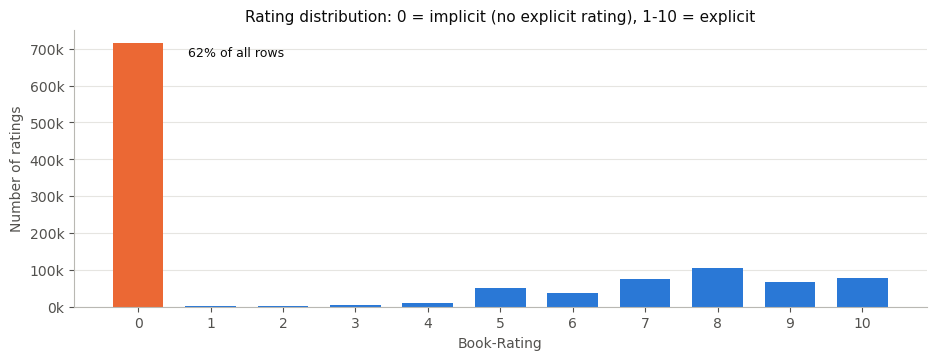

In [6]:
ratings_num = pd.to_numeric(ratings_b["Book-Rating"])
rating_counts = ratings_num.value_counts().sort_index()
zero_share = (ratings_num == 0).mean()
print(f"Ratings equal to 0 (implicit 'no rating'): {(ratings_num == 0).sum():,} ({zero_share:.1%})")
print(f"Explicit ratings 1-10: {(ratings_num > 0).sum():,}")

fig, ax = plt.subplots()
ax.bar(rating_counts.index, rating_counts.values, width=0.7,
       color=[ORANGE if r == 0 else BLUE for r in rating_counts.index])
ax.set_xticks(range(0, 11))
ax.set_xlabel("Book-Rating"); ax.set_ylabel("Number of ratings")
ax.set_title("Rating distribution: 0 = implicit (no explicit rating), 1-10 = explicit")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e3:,.0f}k"))
ax.annotate(f"{zero_share:.0%} of all rows", (0, rating_counts[0]), xytext=(36, -10),
            textcoords="offset points", color=INK, fontsize=9)
plt.show()

* **Ratings:** 716,109 of 1,149,780 ratings (62.3%) are **0**, which means "interacted but did not rate", not "hated it". The 433,671 explicit ratings (1–10) are skewed high: 8 is the most common score and only 2.4% are below 4. → **Silver:** remove all 0 ratings and keep only 1–10. In Step 5, "rated highly" means a rating of 8 or more.

Age: {'count': 168096.0, 'mean': 34.8, 'std': 14.4, 'min': 0.0, '25%': 24.0, '50%': 32.0, '75%': 44.0, 'max': 244.0}
  missing: 110,762 | < 5: 882 | > 100: 366
Year-Of-Publication: {'count': 271379.0, 'mean': 1959.8, 'std': 258.0, 'min': 0.0, '25%': 1989.0, '50%': 1995.0, '75%': 2000.0, 'max': 2050.0}
  year == 0: 4,619 | 0 < year < 1900: 4 | after 2004 (collection year): 72 | after 2026 (today): 11
  impossible future years: [np.int64(2005), np.int64(2006), np.int64(2008), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2020), np.int64(2021), np.int64(2024), np.int64(2026), np.int64(2030), np.int64(2037), np.int64(2038), np.int64(2050)]


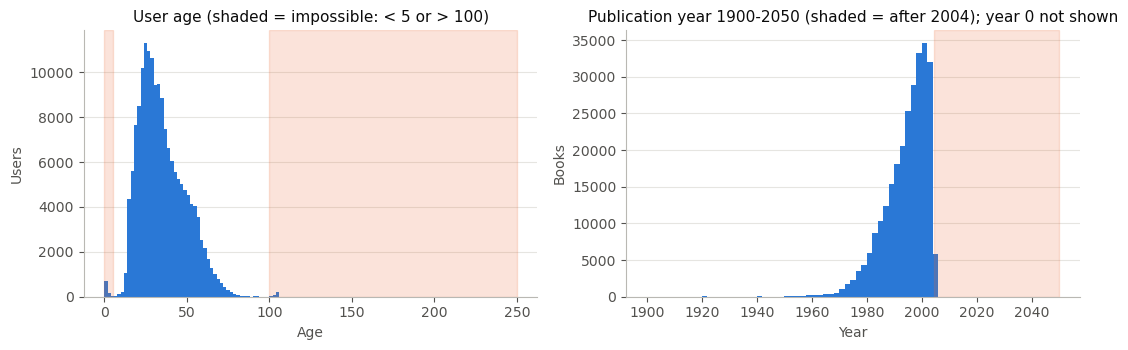

In [7]:
age = pd.to_numeric(users_b["Age"])
year = pd.to_numeric(books_b["Year-Of-Publication"])
DATA_COLLECTION_YEAR = 2004     # Book-Crossing was crawled in Aug-Sep 2004
CURRENT_YEAR = datetime.now().year

print("Age:", age.describe().round(1).to_dict())
print(f"  missing: {age.isna().sum():,} | < 5: {(age < 5).sum():,} | > 100: {(age > 100).sum():,}")
print("Year-Of-Publication:", year.describe().round(1).to_dict())
print(f"  year == 0: {(year == 0).sum():,} | 0 < year < 1900: {((year > 0) & (year < 1900)).sum():,}"
      f" | after {DATA_COLLECTION_YEAR} (collection year): {(year > DATA_COLLECTION_YEAR).sum():,}"
      f" | after {CURRENT_YEAR} (today): {(year > CURRENT_YEAR).sum():,}")
print("  impossible future years:", sorted(year[year > DATA_COLLECTION_YEAR].astype(int).unique()))

fig, axes = plt.subplots(1, 2)
axes[0].hist(age.dropna().clip(upper=250), bins=range(0, 252, 2), color=BLUE)
axes[0].axvspan(0, 5, color=ORANGE, alpha=0.18); axes[0].axvspan(100, 250, color=ORANGE, alpha=0.18)
axes[0].set_title("User age (shaded = impossible: < 5 or > 100)")
axes[0].set_xlabel("Age"); axes[0].set_ylabel("Users")
axes[1].hist(year[(year >= 1900) & (year <= 2050)], bins=range(1900, 2052, 2), color=BLUE)
axes[1].axvspan(DATA_COLLECTION_YEAR + 0.5, 2050, color=ORANGE, alpha=0.18)
axes[1].set_title(f"Publication year 1900-2050 (shaded = after {DATA_COLLECTION_YEAR}); year 0 not shown")
axes[1].set_xlabel("Year"); axes[1].set_ylabel("Books")
plt.tight_layout(); plt.show()

* **User ages:** the median is 32, but values run from 0 to 244. 882 users are under 5 and 366 are over 100, which is impossible for active readers. → **Silver:** set ages < 5 or > 100 to null, then fill all nulls with the median of the valid ages, keeping an `age_imputed` flag.
* **Publication years:** 4,619 books have year **0** (unknown), and 72 books have years after the 2004 crawl, up to 2050. A book rated in 2004 cannot have been published later. → **Silver:** set year 0 and every year after 2004 to null. Using today's date as the cut-off would catch only 11 of the 72.

,all ratings / user,all ratings / book,explicit / user,explicit / book
count,105283.0,340556.0,77805.0,185973.0
mean,10.9,3.4,5.6,2.3
std,90.6,12.4,44.0,6.8
min,1.0,1.0,1.0,1.0
25%,1.0,1.0,1.0,1.0
50%,1.0,1.0,1.0,1.0
75%,4.0,2.0,3.0,2.0
max,13602.0,2502.0,8524.0,707.0


,users with exactly 1 explicit rating,users with >= 10,books with exactly 1 explicit rating,books with >= 10
share,58.3%,9.4%,69.7%,3.0%


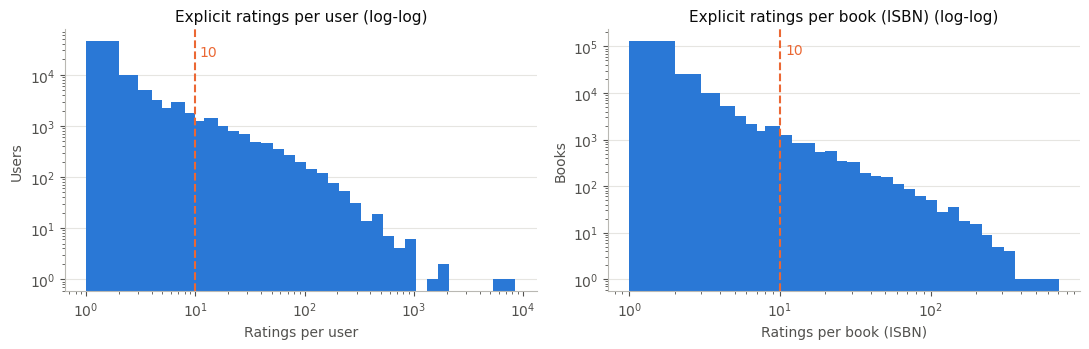

In [8]:
explicit_b = ratings_b[ratings_num > 0]
per_user_all = ratings_b["User-ID"].value_counts()
per_book_all = ratings_b["ISBN"].value_counts()
per_user = explicit_b["User-ID"].value_counts()
per_book = explicit_b["ISBN"].value_counts()

summary = pd.DataFrame({
    "all ratings / user": per_user_all.describe(), "all ratings / book": per_book_all.describe(),
    "explicit / user": per_user.describe(), "explicit / book": per_book.describe(),
}).round(1)
display(summary)

def share(counts, condition):
    return f"{condition(counts).mean():.1%}"
reach = pd.DataFrame({
    "users with exactly 1 explicit rating": [share(per_user, lambda c: c == 1)],
    "users with >= 10": [share(per_user, lambda c: c >= 10)],
    "books with exactly 1 explicit rating": [share(per_book, lambda c: c == 1)],
    "books with >= 10": [share(per_book, lambda c: c >= 10)],
}, index=["share"])
display(reach)

fig, axes = plt.subplots(1, 2)
for ax, counts, label in [(axes[0], per_user, "user"), (axes[1], per_book, "book (ISBN)")]:
    bins = np.unique(np.logspace(0, np.log10(counts.max() + 1), 40).astype(int))
    ax.hist(counts, bins=bins, color=BLUE)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.axvline(10, color=ORANGE, lw=1.5, ls="--"); ax.text(10.8, ax.get_ylim()[1] * 0.3, "10", color=ORANGE)
    ax.set_title(f"Explicit ratings per {label} (log-log)")
    ax.set_xlabel(f"Ratings per {label}"); ax.set_ylabel(f"{label.split()[0].capitalize()}s")
plt.tight_layout(); plt.show()

* **Ratings per user / per book:** the counts follow a long tail. Only 105,283 of 278,858 users rated anything. The median user and the median book have just **1** rating. Of the explicit raters, 58.3% gave exactly one rating and only 9.4% gave 10 or more. Per ISBN, 69.7% have a single explicit rating and only 3.0% have 10 or more. At the other extreme, one user gave 8,524 explicit ratings. → **Silver:** keep only users and books with a minimum number of ratings (chosen in Step 3), because a book seen by one or two readers has no reliable neighbours.

In [9]:
def sparsity_row(label, n_ratings, n_users, n_books):
    density = n_ratings / (n_users * n_books)
    return {"view": label, "ratings": n_ratings, "users": n_users, "books": n_books,
            "possible pairs": n_users * n_books, "filled %": f"{100 * density:.5f}%",
            "sparsity %": f"{100 * (1 - density):.5f}%"}

sparsity = pd.DataFrame([
    sparsity_row("all ratings, all users x all books tables", len(ratings_b), len(users_b), len(books_b)),
    sparsity_row("all ratings, only users/books that appear", len(ratings_b),
                 ratings_b["User-ID"].nunique(), ratings_b["ISBN"].nunique()),
    sparsity_row("explicit ratings only", len(explicit_b),
                 explicit_b["User-ID"].nunique(), explicit_b["ISBN"].nunique()),
])
sparsity

,view,ratings,users,books,possible pairs,filled %,sparsity %
0,"all ratings, all users x all books tables",1149780,278858,271379,75676205182,0.00152%,99.99848%
1,"all ratings, only users/books that appear",1149780,105283,340556,35854757348,0.00321%,99.99679%
2,explicit ratings only,433671,77805,185973,14469629265,0.00300%,99.99700%


* **Sparsity:** only **0.0015%** of the 278,858 × 271,379 possible user–book pairs have a rating, and only 0.0030% of the pairs among explicit raters and rated books. In other words, the matrix is **more than 99.99% empty**. → **Silver/Gold:** the threshold filter will make the matrix far denser, and Gold stores it as a **sparse** (CSR) matrix. A dense float matrix of the full size would need about 300 GB.

## Step 3 — Clean the data and build the Silver layer

Every step is logged so the effect of each rule is visible in the cleaning funnel at the end.

In [10]:
cleaning_log = []
def log(table, step, df):
    cleaning_log.append({"table": table, "step": step, "rows": len(df)})

# ---- text helpers ------------------------------------------------------------
_double_utf8 = re.compile("\u00c3\\?\u00c2([\u0080-\u00bf])")   # 'Ã?Â©' -> 'é' (one byte was lost as '?')

def fix_mojibake(text):
    # Repair UTF-8 text that was decoded as Latin-1 (e.g. 'MÃ©mo' or 'MÃ?Â©mo' -> 'Mémo')
    if not isinstance(text, str) or ("\u00c3" not in text and "\u00c2" not in text):
        return text
    text = _double_utf8.sub(lambda m: chr(0xC0 + ord(m.group(1)) - 0x80), text)
    try:
        return text.encode("latin-1").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return text

def clean_text(s):
    # Decode HTML entities, repair encoding, collapse whitespace, strip; empty -> null
    s = s.map(lambda x: html.unescape(x) if isinstance(x, str) else x).map(fix_mojibake)
    s = s.str.replace(r"\s+", " ", regex=True).str.strip()
    return s.replace("", np.nan)

def title_case(s):
    # Standardise case: 'SUE GRAFTON' / 'sue grafton' -> 'Sue Grafton'; keeps "Sorcerer's" and 'J.K.' correct
    return s.str.lower().str.replace(r"(^|[\s.\-(\"/:])([a-z\u00e0-\u00fe])",
                                     lambda m: m.group(1) + m.group(2).upper(), regex=True)

# Text that means "unknown" (kept verbatim in Bronze, turned into nulls in Silver)
PLACEHOLDERS = {"n/a", "na", "n.a.", "none", "null", "unknown", "not applicable"}

### 3.1 Users: duplicates, ages, location split

In [11]:
users = users_b.drop(columns="ingestion_timestamp").rename(
    columns={"User-ID": "user_id", "Location": "location", "Age": "age"})
log("users", "bronze", users)

users = users.drop_duplicates()
users["user_id"] = users["user_id"].str.strip().astype("int64")
users = users.drop_duplicates(subset="user_id")
log("users", "remove duplicate rows / ids", users)

# Ages: < 5 or > 100 -> null, then fill every null with the median of the valid ages
users["age"] = pd.to_numeric(users["age"])
users.loc[(users["age"] < 5) | (users["age"] > 100), "age"] = np.nan
median_age = users["age"].median()
users["age_imputed"] = users["age"].isna()
users["age"] = users["age"].fillna(median_age).round().astype("int64")
print(f"Median valid age = {median_age:.0f}; imputed for {users['age_imputed'].sum():,} users")

# Location 'city, state, country' -> three columns (middle parts joined if there are > 3 parts)
def clean_place(s):
    s = s.str.strip().str.lower().str.replace(r"\s+", " ", regex=True)
    is_placeholder = s.isin(PLACEHOLDERS) | ~s.fillna("").str.contains(r"[^\W\d_]", regex=True)  # no letters
    return s.mask(is_placeholder)

parts = clean_text(users["location"]).str.lower().str.split(",")
users["city"] = clean_place(parts.str[0])
users["state"] = clean_place(parts.map(lambda p: ",".join(p[1:-1]) if isinstance(p, list) and len(p) >= 3 else np.nan))
users["country"] = clean_place(parts.map(lambda p: p[-1] if isinstance(p, list) and len(p) >= 2 else np.nan))
users["location"] = clean_text(users["location"]).str.lower()

display(users.head())
print("Missing after split:", users[["city", "state", "country"]].isna().sum().to_dict())
print("Top countries:", users["country"].value_counts().head(8).to_dict())

Median valid age = 32; imputed for 112,010 users


,user_id,location,age,age_imputed,city,state,country
0,1,"nyc, new york, usa",32,True,nyc,new york,usa
1,2,"stockton, california, usa",18,False,stockton,california,usa
2,3,"moscow, yukon territory, russia",32,True,moscow,yukon territory,russia
3,4,"porto, v.n.gaia, portugal",17,False,porto,v.n.gaia,portugal
4,5,"farnborough, hants, united kingdom",32,True,farnborough,hants,united kingdom


Missing after split: {'city': 759, 'state': 16499, 'country': 4618}
Top countries: {'usa': 139712, 'canada': 21658, 'united kingdom': 18556, 'germany': 17073, 'spain': 13258, 'australia': 11785, 'italy': 11271, 'france': 3487}


### 3.2 Books: ISBNs, text cleaning, publication year, one `book_id` per title + author

The same book is often listed under several ISBNs (hardcover, paperback, audio, reissues), sometimes with edition notes in the title, e.g. *"Harry Potter And The Sorcerer's Stone (Book 1)"* vs *"… (Harry Potter (Paperback))"*, or *"The Lovely Bones"* vs *"The Lovely Bones: A Novel"*. Their ratings should pool together, and a reader of one edition should not be recommended another. So every ISBN gets a **`book_id`** shared by all ISBNs with the same title and author. For this matching only, the title ignores parenthesised edition notes and a trailing ": A Novel". The ISBN stays as the join key to the ratings.

In [12]:
books = books_b.drop(columns=["ingestion_timestamp", "Image-URL-S", "Image-URL-M", "Image-URL-L"]).rename(
    columns={"ISBN": "isbn", "Book-Title": "title", "Book-Author": "author",
             "Year-Of-Publication": "year", "Publisher": "publisher"})
log("books", "bronze", books)

books = books.drop_duplicates()
books["isbn"] = books["isbn"].str.strip().str.upper()
books = books.drop_duplicates(subset="isbn")
log("books", "remove duplicate rows / ISBNs (after upper-casing)", books)

before = books["title"].copy()
for col in ("title", "author", "publisher"):
    books[col] = title_case(clean_text(books[col]))
for col in ("author", "publisher"):                          # 'None', 'n/a', 'N/A' -> null
    books[col] = books[col].mask(books[col].str.lower().isin(PLACEHOLDERS))
print(f"Titles changed by text cleaning: {(before != books['title']).sum():,}")
print("Missing after cleaning:", books[["title", "author", "publisher"]].isna().sum().to_dict())

# Publication year: 0 or after the 2004 collection date -> null
books["year"] = pd.to_numeric(books["year"])
books.loc[(books["year"] == 0) | (books["year"] > DATA_COLLECTION_YEAR), "year"] = np.nan
books["year"] = books["year"].astype("Int64")
print(f"Years set to null: {books['year'].isna().sum():,}")

# One book_id per (title, author). For matching only, the title drops edition notes in parentheses
# and a trailing ': A Novel', and the author drops punctuation/spaces ('J. K.' == 'J.K.').
def match_title(s):
    t = s.str.lower()
    for _ in range(3):                                       # nested '(Harry Potter (Paperback))'
        t = t.str.replace(r"\s*\([^()]*\)", "", regex=True)
    t = t.str.replace(r"\s*:\s*a novel$", "", regex=True).str.strip()
    return t.where(t != "", s.str.lower())

books["match_title"] = match_title(books["title"])
work_key = books["match_title"] + "|" + books["author"].fillna("").str.lower().str.replace(r"[\W_]", "", regex=True)
books["book_id"] = pd.factorize(work_key)[0]
print(f"{len(books):,} ISBNs -> {books['book_id'].nunique():,} distinct books (title + author)")

books[books["match_title"].isin(["harry potter and the sorcerer's stone", "the lovely bones"])][
    ["isbn", "book_id", "title", "author", "year"]]

Titles changed by text cleaning: 152,944
Missing after cleaning: {'title': 0, 'author': 50, 'publisher': 7}


Years set to null: 4,684


271,064 ISBNs -> 236,804 distinct books (title + author)


,isbn,book_id,title,author,year
408,0316666343,404,The Lovely Bones: A Novel,Alice Sebold,2002
474,0316168815,404,The Lovely Bones,Alice Sebold,2004
2143,059035342X,2049,Harry Potter And The Sorcerer's Stone (Harry Potter (Paperback)),J. K. Rowling,1999
2809,0590353403,2049,Harry Potter And The Sorcerer's Stone (Book 1),J. K. Rowling,1998
9027,043936213X,2049,Harry Potter And The Sorcerer's Stone (Book 1),J. K. Rowling,2001
28428,0807281956,2049,Harry Potter And The Sorcerer's Stone (Book 1 Audio Cd),J. K. Rowling,1999
52581,0807281751,2049,"Harry Potter And The Sorcerer's Stone (Book 1, Audio)",J. K. Rowling,1999
55787,043920352X,2049,Harry Potter And The Sorcerer's Stone (Book 1),J. K. Rowling,2000
72188,0786222727,2049,"Harry Potter And The Sorcerer's Stone (Book 1, Large Print)",J. K. Rowling,1999
88503,1402521154,404,The Lovely Bones,Alice Sebold,2002


### 3.3 Ratings: duplicates, explicit only, referential integrity

In [13]:
ratings = ratings_b.drop(columns="ingestion_timestamp").rename(
    columns={"User-ID": "user_id", "ISBN": "isbn", "Book-Rating": "rating"})
log("ratings", "bronze", ratings)

ratings = ratings.drop_duplicates()
ratings["user_id"] = ratings["user_id"].str.strip().astype("int64")
ratings["isbn"] = ratings["isbn"].str.strip().str.upper()
ratings["rating"] = ratings["rating"].astype("int64")
ratings = ratings.drop_duplicates()
log("ratings", "remove duplicate rows", ratings)

ratings = ratings[ratings["rating"].between(1, 10)]
log("ratings", "remove 0 ratings (keep 1-10)", ratings)

ratings = ratings[ratings["isbn"].isin(books["isbn"]) & ratings["user_id"].isin(users["user_id"])]
log("ratings", "keep only ratings whose book and user exist", ratings)

# Map to book_id; a user who rated several editions of one book gets one (averaged) rating
ratings = ratings.merge(books[["isbn", "book_id"]], on="isbn", how="inner")
ratings = ratings.groupby(["user_id", "book_id"], as_index=False).agg(rating=("rating", "mean"),
                                                                     isbn=("isbn", "first"))
log("ratings", "one rating per user and book (editions merged)", ratings)
print(ratings["rating"].describe().round(2).to_dict())

{'count': 382330.0, 'mean': 7.62, 'std': 1.84, 'min': 1.0, '25%': 7.0, '50%': 8.0, '75%': 9.0, 'max': 10.0}


### 3.4 Minimum-activity threshold

The filter is applied **iteratively**: removing sparse books lowers some users' counts and vice versa, so the two filters repeat until both conditions hold at the same time. The table compares candidate thresholds on the cleaned ratings:

In [14]:
def filter_min_ratings(df, min_user, min_book):
    # Repeat until every user has >= min_user and every book has >= min_book ratings
    rounds = 0
    while True:
        rounds += 1
        n = len(df)
        df = df[df.groupby("user_id")["book_id"].transform("size") >= min_user]
        df = df[df.groupby("book_id")["user_id"].transform("size") >= min_book]
        if len(df) == n:
            return df, rounds

rows = []
for t in (3, 5, 8, 10, 12, 15, 20):
    kept, _ = filter_min_ratings(ratings, t, t)
    n_u, n_b = kept["user_id"].nunique(), kept["book_id"].nunique()
    rows.append({"min ratings (users & books)": t, "ratings": len(kept), "users": n_u, "books": n_b,
                 "density %": round(100 * len(kept) / max(n_u * n_b, 1), 3),
                 "median raters per book": kept.groupby("book_id").size().median() if len(kept) else 0})
pd.DataFrame(rows)

,min ratings (users & books),ratings,users,books,density %,median raters per book
0,3,200454,15395,21376,0.061,5.0
1,5,136947,7809,9328,0.188,8.0
2,8,84851,3709,4064,0.563,13.0
3,10,62836,2472,2632,0.966,16.0
4,12,44336,1631,1672,1.626,19.0
5,15,22245,777,768,3.728,23.0
6,20,0,0,0,0.000,0.0


**Chosen threshold: at least 10 explicit ratings per user and per book.**

* The EDA showed that 58% of explicit raters and 70% of rated ISBNs have exactly **one** explicit rating. Such rows only add noise: a book rated by a single person shares readers with almost no other book, so its cosine similarities are 0 or based on one person.
* With **10**, every book vector has at least 10 raters (median 16), so a similarity rests on real overlap. Density rises from 0.003% to about **1%**, over 300× denser. The model still covers about 2,500 users and 2,600 books, including all the well-known titles.
* Thresholds of 3–5 keep more titles, but the matrix stays very sparse (≤ 0.19%) and the median book has only 5–8 raters. At 15 the catalogue shrinks to about 770 books, and at 20 the iterative filter removes everything. So **10** is the best balance between reliable similarities and a useful catalogue.

In [15]:
MIN_RATINGS = 10
ratings, rounds = filter_min_ratings(ratings, MIN_RATINGS, MIN_RATINGS)
log("ratings", f"users & books with >= {MIN_RATINGS} ratings ({rounds} rounds)", ratings)

users = users[users["user_id"].isin(ratings["user_id"])]
log("users", f"keep users with >= {MIN_RATINGS} ratings", users)
books = books[books["book_id"].isin(ratings["book_id"])]
log("books", f"keep books (all ISBNs) with >= {MIN_RATINGS} ratings", books)

# Final consistency checks
assert ratings["user_id"].isin(users["user_id"]).all() and ratings["book_id"].isin(books["book_id"]).all()
assert ratings.groupby("user_id").size().min() >= MIN_RATINGS and ratings.groupby("book_id").size().min() >= MIN_RATINGS
assert ratings["rating"].between(1, 10).all() and not ratings.duplicated(["user_id", "book_id"]).any()
assert users["age"].between(5, 100).all()

users.to_parquet(SILVER / "users.parquet", index=False)
books.to_parquet(SILVER / "books.parquet", index=False)
ratings.to_parquet(SILVER / "ratings.parquet", index=False)

print("Cleaning funnel:")
display(pd.DataFrame(cleaning_log))
print("Silver files:", {p.name: f"{p.stat().st_size / 1e6:.2f} MB" for p in sorted(SILVER.glob('*.parquet'))})

Cleaning funnel:


,table,step,rows
0,users,bronze,278858
1,users,remove duplicate rows / ids,278858
2,books,bronze,271379
3,books,remove duplicate rows / ISBNs (after upper-casing),271064
4,ratings,bronze,1149780
5,ratings,remove duplicate rows,1149780
6,ratings,remove 0 ratings (keep 1-10),433671
7,ratings,keep only ratings whose book and user exist,383853
8,ratings,one rating per user and book (editions merged),382330
9,ratings,users & books with >= 10 ratings (6 rounds),62836


Silver files: {'books.parquet': '0.34 MB', 'ratings.parquet': '0.32 MB', 'users.parquet': '0.07 MB'}


## Step 4 — Build the Gold layer

Model-ready outputs, all built only from Silver:

| File | Content |
|---|---|
| `user_book_matrix.npz` | sparse CSR matrix, rows = users, columns = books, values = rating (1–10) |
| `matrix_user_index.parquet` / `matrix_book_index.parquet` | row → `user_id`, column → `book_id` |
| `book_lookup.parquet` | `book_id`, title, author, year, publisher, number of ISBNs/editions |
| `user_stats.parquet` / `book_stats.parquet` | average rating and number of ratings per user / per book |

In [16]:
silver_users = pd.read_parquet(SILVER / "users.parquet")
silver_books = pd.read_parquet(SILVER / "books.parquet")
silver_ratings = pd.read_parquet(SILVER / "ratings.parquet")

# --- user-book rating matrix (sparse) -----------------------------------------
user_ids = np.sort(silver_ratings["user_id"].unique())
book_ids = np.sort(silver_ratings["book_id"].unique())
rows = np.searchsorted(user_ids, silver_ratings["user_id"].to_numpy())
cols = np.searchsorted(book_ids, silver_ratings["book_id"].to_numpy())
user_book = sparse.csr_matrix((silver_ratings["rating"].to_numpy(np.float32), (rows, cols)),
                              shape=(len(user_ids), len(book_ids)))

sparse.save_npz(GOLD / "user_book_matrix.npz", user_book)
pd.DataFrame({"row": range(len(user_ids)), "user_id": user_ids}).to_parquet(GOLD / "matrix_user_index.parquet", index=False)
pd.DataFrame({"col": range(len(book_ids)), "book_id": book_ids}).to_parquet(GOLD / "matrix_book_index.parquet", index=False)

dense_mb = user_book.shape[0] * user_book.shape[1] * 4 / 1e6
sparse_mb = (user_book.data.nbytes + user_book.indices.nbytes + user_book.indptr.nbytes) / 1e6
print(f"Matrix: {user_book.shape[0]:,} users x {user_book.shape[1]:,} books, {user_book.nnz:,} ratings, "
      f"density {100 * user_book.nnz / np.prod(user_book.shape):.2f}%")
print(f"Memory: sparse {sparse_mb:.2f} MB vs dense {dense_mb:.1f} MB")

# --- book lookup -----------------------------------------------------------------
# Display title = the shortest edition title (usually the plain one, without edition notes)
silver_books["title_len"] = silver_books["title"].str.len()
book_lookup = (silver_books.sort_values(["book_id", "title_len"]).groupby("book_id")
               .agg(title=("title", "first"), author=("author", "first"), year=("year", "min"),
                    publisher=("publisher", "first"), n_isbns=("isbn", "size"),
                    isbns=("isbn", lambda s: ", ".join(sorted(s))))
               .reset_index())
book_lookup.to_parquet(GOLD / "book_lookup.parquet", index=False)

# --- user-level and book-level aggregates -------------------------------------
global_mean = silver_ratings["rating"].mean()
book_stats = (silver_ratings.groupby("book_id")["rating"].agg(n_ratings="size", avg_rating="mean").reset_index()
              .merge(book_lookup[["book_id", "title", "author"]], on="book_id"))
# Bayesian (damped) average: pulls books with few ratings toward the global mean
book_stats["weighted_rating"] = ((book_stats["n_ratings"] * book_stats["avg_rating"] + MIN_RATINGS * global_mean)
                                 / (book_stats["n_ratings"] + MIN_RATINGS))
user_stats = (silver_ratings.groupby("user_id")["rating"]
              .agg(n_ratings="size", avg_rating="mean", min_rating="min", max_rating="max").reset_index()
              .merge(silver_users[["user_id", "age", "age_imputed", "city", "state", "country"]], on="user_id"))
book_stats.to_parquet(GOLD / "book_stats.parquet", index=False)
user_stats.to_parquet(GOLD / "user_stats.parquet", index=False)

print("Gold files:", {p.name: f"{p.stat().st_size / 1e6:.2f} MB" for p in sorted(GOLD.iterdir())})
print("\nMost-rated books:")
display(book_stats.sort_values("n_ratings", ascending=False).head(8).round(2))
print("User aggregates:")
display(user_stats[["n_ratings", "avg_rating"]].describe().round(2).T)

Matrix: 2,472 users x 2,632 books, 62,836 ratings, density 0.97%
Memory: sparse 0.51 MB vs dense 26.0 MB
Gold files: {'book_lookup.parquet': '0.18 MB', 'book_stats.parquet': '0.11 MB', 'matrix_book_index.parquet': '0.03 MB', 'matrix_user_index.parquet': '0.03 MB', 'user_book_matrix.npz': '0.15 MB', 'user_stats.parquet': '0.06 MB'}

Most-rated books:


,book_id,n_ratings,avg_rating,title,author,weighted_rating
158,404,277,8.27,The Lovely Bones,Alice Sebold,8.26
629,2049,231,9.03,Harry Potter And The Sorcerer's Stone,J. K. Rowling,8.98
260,732,209,8.62,The Da Vinci Code,Dan Brown,8.59
182,476,189,7.74,She's Come Undone,Wally Lamb,7.75
138,353,186,8.65,The Secret Life Of Bees,Sue Monk Kidd,8.61
838,3293,180,8.93,Harry Potter And The Chamber Of Secrets,J. K. Rowling,8.88
912,3639,167,9.10,Harry Potter And The Prisoner Of Azkaban,J. K. Rowling,9.03
68,166,162,7.69,Bridget Jones's Diary,Helen Fielding,7.70


User aggregates:


,count,mean,std,min,25%,50%,75%,max
n_ratings,2472.0,25.42,35.22,10.00,12.00,17.00,28.00,1325.0
avg_rating,2472.0,7.90,0.94,4.27,7.33,7.93,8.54,10.0


## Step 5 — Item-based collaborative filtering

1. Load the rating matrix from Gold and transpose it so that **each row is a book and each column is a user**.
2. Fit `NearestNeighbors(metric="cosine")` on that sparse matrix. Two books are similar when the same readers rated both, and rated them similarly.
3. `similar_books(title)` returns the 10 most similar books.
4. `recommend(user_id, n=10)` takes the books the user rated highly (≥ 8), collects each one's nearest neighbours, and scores each candidate as **Σ similarity × the user's rating** of the liked book. It then removes books the user has already rated and returns the top *n*.

In [17]:
# 5.1 Load Gold and arrange as book x user
user_book = sparse.load_npz(GOLD / "user_book_matrix.npz").tocsr()
user_ids = pd.read_parquet(GOLD / "matrix_user_index.parquet")["user_id"].to_numpy()
book_ids = pd.read_parquet(GOLD / "matrix_book_index.parquet")["book_id"].to_numpy()
book_lookup = pd.read_parquet(GOLD / "book_lookup.parquet").set_index("book_id")
book_stats = pd.read_parquet(GOLD / "book_stats.parquet").set_index("book_id")
user_stats = pd.read_parquet(GOLD / "user_stats.parquet").set_index("user_id")

book_user = user_book.T.tocsr()                       # rows = books, columns = users
user_pos = {u: i for i, u in enumerate(user_ids)}
titles = book_lookup.loc[book_ids, "title"].to_numpy()
authors = book_lookup.loc[book_ids, "author"].to_numpy()
n_ratings_per_book = np.diff(book_user.indptr)
print(f"book x user matrix: {book_user.shape[0]:,} books x {book_user.shape[1]:,} users, {book_user.nnz:,} ratings")

book x user matrix: 2,632 books x 2,472 users, 62,836 ratings


In [18]:
# 5.2 Cosine similarity between books with NearestNeighbors
N_NEIGHBORS = 20      # neighbours kept per book (chosen with the hold-out check in Step 6)

def fit_item_knn(book_user_matrix, k=N_NEIGHBORS):
    # Return (model, neighbour indices, cosine similarities) for every book, excluding the book itself
    model = NearestNeighbors(metric="cosine", algorithm="brute", n_neighbors=k + 1)
    model.fit(book_user_matrix)
    distances, indices = model.kneighbors(book_user_matrix)
    sims = 1.0 - distances
    sims[indices == np.arange(len(indices))[:, None]] = -np.inf   # drop self wherever it appears
    order = np.argsort(-sims, axis=1)[:, :k]
    return model, np.take_along_axis(indices, order, axis=1), np.take_along_axis(sims, order, axis=1)

knn_model, neigh_idx, neigh_sim = fit_item_knn(book_user)
print("Neighbour table:", neigh_idx.shape, "| mean similarity of nearest neighbour:", neigh_sim[:, 0].mean().round(3))

Neighbour table: (2632, 20) | mean similarity of nearest neighbour: 0.34


In [19]:
# 5.3 The 10 most similar books to a given title
def find_book(title):
    # Titles equal to or starting with the query first, otherwise any title containing it; ties -> most-rated
    t = title.strip().lower()
    lower_titles = pd.Series(titles).str.lower()
    matches = np.flatnonzero(lower_titles.str.startswith(t))
    if len(matches) == 0:
        matches = np.flatnonzero(lower_titles.str.contains(t, regex=False))
    if len(matches) == 0:
        raise ValueError(f"No book in the model matches {title!r}")
    return matches[np.argmax(n_ratings_per_book[matches])]

def similar_books(title, n=10):
    i = find_book(title)
    distances, indices = knn_model.kneighbors(book_user[i], n_neighbors=n + 1)
    pairs = [(j, 1 - d) for j, d in zip(indices[0], distances[0]) if j != i][:n]
    print(f"Books most similar to: {titles[i]} — {authors[i]} ({n_ratings_per_book[i]} ratings)")
    return pd.DataFrame({"title": [titles[j] for j, _ in pairs], "author": [authors[j] for j, _ in pairs],
                         "similarity": [round(s, 3) for _, s in pairs]}, index=pd.RangeIndex(1, len(pairs) + 1))

similar_books("Harry Potter and the Sorcerer's Stone")

Books most similar to: Harry Potter And The Sorcerer's Stone — J. K. Rowling (231 ratings)


,title,author,similarity
1,Harry Potter And The Chamber Of Secrets,J. K. Rowling,0.608
2,Harry Potter And The Prisoner Of Azkaban,J. K. Rowling,0.556
3,Harry Potter And The Goblet Of Fire,J. K. Rowling,0.512
4,Harry Potter And The Order Of The Phoenix (Book 5),J. K. Rowling,0.376
5,The Fellowship Of The Ring,J. R. R. Tolkien,0.227
6,The Two Towers,J. R. R. Tolkien,0.197
7,The Return Of The King,J. R. R. Tolkien,0.195
8,Anne Of Green Gables,L.M. Montgomery,0.159
9,The Hobbit : The Enchanting Prelude To The Lord Of The Rings,J.R.R. Tolkien,0.158
10,Charlotte's Web,E. B. White,0.151


In [20]:
display(similar_books("The Lovely Bones"))
display(similar_books("The Da Vinci Code"))

Books most similar to: The Lovely Bones — Alice Sebold (277 ratings)


,title,author,similarity
1,Lucky : A Memoir,Alice Sebold,0.202
2,She's Come Undone,Wally Lamb,0.200
3,White Oleander,Janet Fitch,0.198
4,Where The Heart Is,Billie Letts,0.197
5,The Pilot's Wife,Anita Shreve,0.181
6,The Da Vinci Code,Dan Brown,0.173
7,Good In Bed,Jennifer Weiner,0.170
8,The Dive From Clausen's Pier (Alex Awards),Ann Packer,0.167
9,The Secret Life Of Bees,Sue Monk Kidd,0.155
10,Lucky,Alice Sebold,0.154


Books most similar to: The Da Vinci Code — Dan Brown (209 ratings)


,title,author,similarity
1,Angels & Demons,Dan Brown,0.248
2,Middlesex,Jeffrey Eugenides,0.185
3,The Lovely Bones,Alice Sebold,0.173
4,The Secret Life Of Bees,Sue Monk Kidd,0.171
5,The Narrows: A Novel,Michael Connelly,0.162
6,The Curious Incident Of The Dog In The Night-Time,Mark Haddon,0.152
7,Street Dreams,Faye Kellerman,0.142
8,Digital Fortress : A Thriller,Dan Brown,0.141
9,The Conspiracy Club,Jonathan Kellerman,0.139
10,The Sweet Potato Queens' Book Of Love,Jill Conner Browne,0.136


In [21]:
# 5.4 recommend(user_id, n=10)
HIGH_RATING = 8                     # "rated highly" = 8, 9 or 10
popular_cols = np.argsort(-n_ratings_per_book, kind="stable")    # fallback order: most-rated first

def score_books(rated_cols, rated_vals, nb_idx, nb_sim, min_rating=HIGH_RATING):
    # Score every book: sum over the user's liked books of similarity x the user's rating of that book
    liked = rated_vals >= min_rating
    if not liked.any():                                   # nothing >= 8: use the user's above-average books
        liked = rated_vals >= rated_vals.mean()
    seeds, weights = rated_cols[liked], rated_vals[liked]
    contrib = nb_sim[seeds] * weights[:, None]            # (n_liked, k)
    cand = nb_idx[seeds]
    scores = np.zeros(nb_idx.shape[0])
    np.add.at(scores, cand.ravel(), contrib.ravel())
    scores[rated_cols] = 0.0                              # remove books the user already rated
    # strongest single reason for each candidate ("because you liked ...")
    reasons = (pd.DataFrame({"cand": cand.ravel(), "seed": np.repeat(seeds, cand.shape[1]), "c": contrib.ravel()})
               .sort_values("c").drop_duplicates("cand", keep="last").set_index("cand")["seed"])
    return scores, reasons

def top_n(scores, rated_cols, popular_order, n=10):
    # Highest-scoring unread books; if fewer than n have a positive score, pad with popular unread books
    ranked = np.argsort(-scores, kind="stable")
    top = [c for c in ranked[:n] if scores[c] > 0]
    if len(top) < n:
        seen = set(rated_cols) | set(top)
        top += [c for c in popular_order[: n + len(seen)] if c not in seen][: n - len(top)]
    return top

def recommend(user_id, n=10, min_rating=HIGH_RATING):
    # Top-n book recommendations for one user, as a table of readable titles
    if user_id not in user_pos:                           # cold start: user not in the Gold matrix
        print(f"User {user_id} has no ratings in the model -> most-rated books instead")
        top = popular_cols[:n]
        return pd.DataFrame({"title": titles[top], "author": authors[top], "score": np.nan,
                             "because_you_liked": "(popular)", "book_id": book_ids[top]},
                            index=pd.RangeIndex(1, n + 1))
    row = user_book[user_pos[user_id]]
    scores, reasons = score_books(row.indices, row.data, neigh_idx, neigh_sim, min_rating)
    top = top_n(scores, row.indices, popular_cols, n)
    return pd.DataFrame({
        "title": titles[top], "author": authors[top], "score": np.round(scores[top], 2),
        "because_you_liked": [titles[reasons[c]] if c in reasons.index and scores[c] > 0 else "(popular)"
                              for c in top],
        "book_id": book_ids[top],
    }, index=pd.RangeIndex(1, len(top) + 1))

example_user = user_stats.sort_values("n_ratings", ascending=False).index[5]
recommend(example_user)

,title,author,score,because_you_liked,book_id
1,N Is For Noose,Sue Grafton,40.85,J Is For Judgment,6379
2,The Anastasia Syndrome,Mary Higgins Clark,32.35,You Belong To Me,5886
3,The Face Of Fear,Dean R. Koontz,31.03,Changes,9870
4,Angel,Johanna Lindsey,25.46,Say You Love Me,23601
5,Little Town On The Prairie,Laura Ingalls Wilder,25.04,The Long Winter,22142
6,To The Nines: A Stephanie Plum Novel,Janet Evanovich,21.96,Seven Up,2878
7,Garden Of Shadows (Dollanger Saga (Paperback)),Ariel Jennifer Jones,21.88,Heaven,17765
8,Counterfeit Lady,Jude Deveraux,18.59,A Knight In Shining Armor,16862
9,Harry Potter And The Order Of The Phoenix (Book 5),J. K. Rowling,18.05,Harry Potter And The Goblet Of Fire,5184
10,Warrior's Woman,Johanna Lindsey,17.16,Keeper Of The Heart,20481


## Step 6 — Demo and sanity check

### 6.1 Recommendations for three users

Three users are drawn at random (fixed seed) from users with a typical activity level (15–60 ratings, at least 5 rated ≥ 8). For each one, the books they rated highly are shown **next to** the recommendations.

In [22]:
def show_user(user_id, n=10):
    recs = recommend(user_id, n)
    if user_id in user_pos:
        info = user_stats.loc[user_id]
        where = ", ".join(str(x) for x in (info["city"], info["country"]) if isinstance(x, str))
        print(f"User {user_id} | age {info['age']}{' (imputed)' if info['age_imputed'] else ''} | {where} | "
              f"{info['n_ratings']} ratings, average {info['avg_rating']:.1f}")
        row = user_book[user_pos[user_id]]
        liked = pd.DataFrame({"col": row.indices, "rating": row.data})
        liked = liked[liked["rating"] >= HIGH_RATING].sort_values("rating", ascending=False, kind="stable")
        liked_text = [f"{titles[c]} — {authors[c]} ({r:g})" for c, r in zip(liked["col"], liked["rating"])]
        assert not set(book_ids[row.indices]) & set(recs["book_id"]), "recommended a book the user already rated"
        assert len(recs) == n and recs["book_id"].is_unique
    else:
        liked_text = []
    rec_text = [f"{t} — {a}" for t, a in zip(recs["title"], recs["author"])]
    width = max(len(rec_text), min(len(liked_text), n))
    pad = lambda xs: (xs + [""] * width)[:width]
    side_by_side = pd.DataFrame({f"Rated highly (>= {HIGH_RATING}), top {min(len(liked_text), n)} of {len(liked_text)}": pad(liked_text),
                                 "Recommended": pad(rec_text),
                                 "Because the user liked": pad(list(recs["because_you_liked"]))},
                                index=pd.RangeIndex(1, width + 1))
    display(side_by_side.style.set_properties(**{"text-align": "left"})
            .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))
    return recs

high_counts = pd.Series(np.asarray((user_book >= HIGH_RATING).sum(axis=1)).ravel(), index=user_ids)
eligible = user_stats[user_stats["n_ratings"].between(15, 60) & (high_counts.reindex(user_stats.index) >= 5)]
demo_users = eligible.sample(3, random_state=RANDOM_STATE).index.tolist()
print("Demo users:", demo_users)

Demo users: [140000, 207148, 128835]


In [23]:
recs_1 = show_user(demo_users[0])

User 140000 | age 32 (imputed) | london, united kingdom | 54 ratings, average 7.6


,"Rated highly (>= 8), top 10 of 31",Recommended,Because the user liked
1,Atonement — Ian Mcewan (10),Two For The Dough — Janet Evanovich,One For The Money (A Stephanie Plum Novel)
2,"The Amber Spyglass (His Dark Materials, Book 3) — Philip Pullman (10)","The Golden Compass (His Dark Materials, Book 1) — Philip Pullman","The Amber Spyglass (His Dark Materials, Book 3)"
3,The Lovely Bones — Alice Sebold (10),High Five (A Stephanie Plum Novel) — Janet Evanovich,Four To Score (A Stephanie Plum Novel)
4,Where The Heart Is — Billie Letts (10),Three To Get Deadly : A Stephanie Plum Novel — Janet Evanovich,Four To Score (A Stephanie Plum Novel)
5,The No. 1 Ladies' Detective Agency — Alexander Mccall Smith (10),Hot Six : A Stephanie Plum Novel (A Stephanie Plum Novel) — Janet Evanovich,Four To Score (A Stephanie Plum Novel)
6,The Last Time They Met: A Novel — Anita Shreve (10),Tears Of The Giraffe — Alexander Mccall-Smith,The No. 1 Ladies' Detective Agency
7,An Instance Of The Fingerpost — Iain Pears (10),Seven Up — Janet Evanovich,Four To Score (A Stephanie Plum Novel)
8,Year Of Wonders — Geraldine Brooks (10),Over The Edge — Suzanne Brockmann,The Sinner
9,Lasher — Anne Rice (10),Dark Horse — Tami Hoag,The Sinner
10,Grave Secrets — Kathy Reichs (10),The Dive From Clausen's Pier (Alex Awards) — Ann Packer,Atonement


In [24]:
recs_2 = show_user(demo_users[1])

User 207148 | age 42 | san diego, usa | 22 ratings, average 8.0


,"Rated highly (>= 8), top 10 of 16",Recommended,Because the user liked
1,Confessions Of A Shopaholic — Sophie Kinsella (10),Strange Fits Of Passion — Anita Shreve,Eden Close
2,The Hours — Michael Cunningham (10),Timepiece — Richard Paul Evans,Eden Close
3,Eden Close — Anita Shreve (10),Sea Glass — Anita Shreve,Fortune's Rocks
4,Fortune's Rocks — Anita Shreve (10),Durable Goods — Elizabeth Berg,Talk Before Sleep
5,Echoes — Maeve Binchy (9),Shopaholic Takes Manhattan — Sophie Kinsella,Confessions Of A Shopaholic
6,The Mistress Of Spices — Chitra Banerjee Divakaruni (9),Blue Diary — Alice Hoffman,Fortune's Rocks
7,Talk Before Sleep — Elizabeth Berg (9),Cold Mountain — Charles Frazier,The Hours
8,The Pact: A Love Story — Jodi Picoult (9),Lightning — Danielle Steel,Coast Road
9,Cheet (Plume Books) — Anna Davis (9),All He Ever Wanted — Anita Shreve,Eden Close
10,Dead Run — Erica Spindler (8),The Last Time They Met: A Novel — Anita Shreve,Eden Close


In [25]:
recs_3 = show_user(demo_users[2])

User 128835 | age 60 | bellingham, usa | 57 ratings, average 8.5


,"Rated highly (>= 8), top 10 of 51",Recommended,Because the user liked
1,Sense And Sensibility — Jane Austen (10),The Dark Half — Stephen King,Four Past Midnight
2,Different Seasons — Stephen King (10),Desperation — Stephen King,Bag Of Bones
3,The Once And Future King — T. H. White (10),Insomnia — Stephen King,Bag Of Bones
4,The Life And Loves Of A She-Devil — Fay Weldon (10),Nightmares & Dreamscapes — Stephen King,Four Past Midnight
5,Circle Of Friends — Maeve Binchy (9.5),"The Drawing Of The Three (The Dark Tower, Book 2) — Stephen King",The Stand
6,"The Golden Compass (His Dark Materials, Book 1) — Philip Pullman (9)",Rose Madder — Stephen King,Four Past Midnight
7,Dreamcatcher — Stephen King (9),Dolores Claiborne — Stephen King,Different Seasons
8,The Dead Zone — Stephen King (9),Pet Sematary — Stephen King,Christine
9,The Princess Bride: S Morgenstern's Classic Tale Of True Love And High Adventure — William Goldman (9),Misery — Stephen King,Christine
10,Lake Wobegon Days — Garrison Keillor (9),Carrie — Stephen King,Christine


### 6.2 Edge case: a user with no ratings in the model (cold start)

User `1` exists in the raw users table but rated nothing, so item-based CF has no seed books. `recommend` falls back to the most-rated books.

In [26]:
recommend(1)

User 1 has no ratings in the model -> most-rated books instead


,title,author,score,because_you_liked,book_id
1,The Lovely Bones,Alice Sebold,NaN,(popular),404
2,Harry Potter And The Sorcerer's Stone,J. K. Rowling,NaN,(popular),2049
3,The Da Vinci Code,Dan Brown,NaN,(popular),732
4,She's Come Undone,Wally Lamb,NaN,(popular),476
5,The Secret Life Of Bees,Sue Monk Kidd,NaN,(popular),353
6,Harry Potter And The Chamber Of Secrets,J. K. Rowling,NaN,(popular),3293
7,Harry Potter And The Prisoner Of Azkaban,J. K. Rowling,NaN,(popular),3639
8,Bridget Jones's Diary,Helen Fielding,NaN,(popular),166
9,Divine Secrets Of The Ya-Ya Sisterhood,Rebecca Wells,NaN,(popular),400
10,The Red Tent,Anita Diamant,NaN,(popular),512


### 6.3 Quantitative sanity check: does the recommender find books a user really liked?

**Leave-one-out test.** For 600 random users with at least 3 books rated ≥ 8, hide one of those books, rebuild the similarity model **without** it, and check whether the hidden book appears in that user's top 10 (**hit rate @10**). For comparison:
* a **popularity** baseline recommends the 10 most-rated books the user has not read;
* a **random** baseline would hit only about 10 / 2,400 ≈ 0.4% of the time.

In [27]:
rng = np.random.default_rng(RANDOM_STATE)
coo = user_book.tocoo()
long = pd.DataFrame({"row": coo.row, "col": coo.col, "rating": coo.data})
high = long[long["rating"] >= HIGH_RATING]
candidates = high.groupby("row").size()
test_rows = rng.choice(candidates[candidates >= 3].index.to_numpy(), size=600, replace=False)
held_out = high[high["row"].isin(test_rows)].groupby("row").sample(1, random_state=RANDOM_STATE)

train = long.drop(held_out.index)
train_ub = sparse.csr_matrix((train["rating"], (train["row"], train["col"])), shape=user_book.shape)
train_bu = train_ub.T.tocsr()
train_popular = np.argsort(-np.diff(train_bu.indptr), kind="stable")

def hit_rate(nb_idx, nb_sim, n=10):
    cf_hits = pop_hits = 0
    for r, hidden in zip(held_out["row"], held_out["col"]):
        row = train_ub[r]
        scores, _ = score_books(row.indices, row.data, nb_idx, nb_sim)
        cf_hits += hidden in top_n(scores, row.indices, train_popular, n)
        pop_hits += hidden in top_n(np.zeros(len(scores)), row.indices, train_popular, n)
    return cf_hits / len(held_out), pop_hits / len(held_out)

results = []
for k in (10, 20, 50):
    _, idx_k, sim_k = fit_item_knn(train_bu, k)
    cf, pop = hit_rate(idx_k, sim_k)
    results.append({"neighbours per book (k)": k, "item-CF hit@10": f"{cf:.1%}", "popularity hit@10": f"{pop:.1%}",
                    "random hit@10 (approx.)": f"{10 / user_book.shape[1]:.1%}"})
pd.DataFrame(results)

,neighbours per book (k),item-CF hit@10,popularity hit@10,random hit@10 (approx.)
0,10,13.3%,3.8%,0.4%
1,20,13.5%,3.8%,0.4%
2,50,13.0%,3.8%,0.4%


**Result:** item-based CF finds the hidden book about **3.5× more often than the popularity baseline** and about **30× more often than random** (13.5% vs 3.8% vs 0.4% with k = 20). The scores are similar for k = 10–50, so the model is not sensitive to this setting. k = 20 scored best and is the value used above. Hit@10 is a strict test, since only one specific hidden book counts as a hit.

## Conclusions

* **Bronze → Silver → Gold.** The 1,149,780 raw ratings shrink to 433,671 explicit ratings, then 383,853 with a known book and user, 382,330 after merging editions, and **62,836** after the minimum-10 filter. The final model covers **2,472 users × 2,632 books** at 0.97% density, held in a 0.5 MB sparse matrix instead of a 26 MB dense one.
* **The recommender behaves sensibly.** Similar books stay in the same series, author or genre (*Harry Potter* → the other *Harry Potter* books, then Tolkien; *The Da Vinci Code* → *Angels & Demons*). The three demo users get recommendations that clearly follow what they rated highly: a Stephen King fan gets more King, an Anita Shreve reader gets more Shreve and similar literary fiction, and a Stephanie Plum / *His Dark Materials* reader gets the other books in those series. No user is recommended a book they already rated (checked with `assert`).
* **Limitations.** Raw cosine on all-positive ratings mostly measures *who read both books*, so popular books and same-author books dominate. Users and books below 10 ratings are not covered: new users get the popularity fallback. Some editions still differ by subtitle (e.g. *Lucky* vs *Lucky: A Memoir*). Next steps would be mean-centred (adjusted) cosine, using the implicit 0-ratings as an extra signal, and a hybrid with content features (author, publisher).